In Chapter 20a, we saw what foundation models are and how the main ones are built. In this second part, we use them. Nearly all open foundation models are written in **PyTorch**, the deep-learning library we met at the end of Chapter 19, and distributed through the **Hugging Face Hub**, an online repository of pretrained models. Each model comes with a small Python package that downloads the weights, scales and tokenizes the series, runs the network and turns its output back into forecasts, so that a forecast takes three or four lines of code.

We first collect the few PyTorch notions that these packages rely on, then go through the functions of each model, without the details of their code, and finish with one case study: the Rome electricity load of Chapters 16 to 19, forecast 24 hours ahead without any training, and compared with every model of those chapters.

# Learning objectives

By the end of this lecture, you should be able to

1. explain the PyTorch objects that a pretrained forecasting model is made of (tensors, modules, parameters, devices, inference mode) and how its weights are loaded from the Hugging Face Hub;
2. call Chronos, Chronos-Bolt, Chronos-2 and TimesFM from Python, and read their outputs: sample paths, quantiles and point forecasts;
3. recognize the corresponding functions of Moirai, Tiny Time Mixers, Lag-Llama and TimeGPT;
4. forecast a series zero-shot, evaluate the forecasts and their prediction intervals on a validation and a test period, and compare them with trained models;
5. explain how the length of the context changes a zero-shot forecast.

# Setup

Modules and functions used in this lecture.

| Module | Used for |
|---|---|
| `torch` | `tensor`, `stack`, `manual_seed`, `inference_mode` -- the deep-learning library under every model |
| `chronos` | `BaseChronosPipeline` -- Chronos, Chronos-Bolt and Chronos-2, from Amazon |
| `timesfm` | `TimesFM_2p5_200M_torch`, `ForecastConfig` -- TimesFM 2.5, from Google |
| `numpy` | arrays |
| `pandas` | `read_csv`, `DataFrame` |
| `matplotlib.pyplot` | `subplots`, `plot`, `fill_between` |
| `time` | `perf_counter` -- timing the forecasts |

**Installation.** The two model packages are installed with pip, which also installs PyTorch and the Hugging Face libraries,

```
pip install chronos-forecasting "timesfm[torch]"
```

On Windows and macOS, this installs the version of PyTorch that runs on the Central Processing Unit (CPU); on a machine with an NVIDIA graphics card, the [PyTorch website](https://pytorch.org/get-started/locally/) gives the command for a version that uses it. The first call of each model downloads its weights from the Hugging Face Hub, about 1.7 GB for the four models of this chapter, into a local cache (`~/.cache/huggingface`); later calls load them from there. Everything below runs on a CPU.

In [1]:
import os
import time
import warnings

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"       # no download progress bars in the notes
os.environ["HF_HUB_VERBOSITY"] = "error"               # nor messages from the Hugging Face Hub
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import timesfm
from chronos import BaseChronosPipeline

torch.manual_seed(8990)                                # Chronos samples its forecasts
print(f"PyTorch {torch.__version__}, {torch.get_num_threads()} CPU threads, "
      f"graphics card available: {torch.cuda.is_available()}")

PyTorch 2.15.0+cpu, 4 CPU threads, graphics card available: False


Self-defined functions carried over from earlier chapters: the run-sequence plot (Chapter 4) and the MSE (Chapter 6).

In [2]:
def run_sequence_plot(y, x=None, title="", xlabel="time", ylabel="value",
                      ax=None, figsize=(9, 3), color="blue", **kwargs):
    "Plot a series against time and return the axes."
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    if x is None:
        x = getattr(y, "index", np.arange(len(y)))
    ax.plot(x, y, color=color, lw=1, **kwargs)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.grid(alpha=0.3)
    return ax


def mse(observations, estimates):
    "Mean squared error between two equal-length sequences."
    observations = np.asarray(observations, dtype=float)
    estimates = np.asarray(estimates, dtype=float)
    if observations.shape != estimates.shape:
        raise ValueError(f"shape mismatch: {observations.shape} vs {estimates.shape}")
    return np.mean((observations - estimates) ** 2)

---

# PyTorch essentials

A pretrained forecasting model is an `nn.Module`, the PyTorch class from which we built the `PatchTransformer` at the end of Chapter 19: an object that holds its **parameters**, tensors of weights, and defines the forward pass. To use one for forecasting, a few notions are enough.

- **Tensors.** A tensor is PyTorch's array. `torch.tensor(a, dtype=torch.float32)` turns a NumPy array into a tensor and `.numpy()` turns it back. The models expect 32-bit floats.
- **Batches.** Several series are forecast at once by stacking their contexts as the rows of a two-dimensional tensor of shape (batch, time), or of shape (batch, variates, time) for a multivariate model. The packages also accept a list of one-dimensional tensors of different lengths: they pad the shorter ones on the left with missing values, `torch.nan`, and a **mask** tells the attention to ignore them.
- **Inference mode.** `model.eval()` switches off training-only behaviour, such as dropout, and `torch.inference_mode()` stops PyTorch from recording the operations for backpropagation, which saves memory and time. The forecasting functions of the packages do both.
- **Devices.** Parameters and tensors live on a device, `"cpu"` or `"cuda"` for an NVIDIA graphics card, and the packages take a `device_map` or `device` argument.
- **Pretrained weights.** `from_pretrained("organization/model-name")` downloads a configuration file and a weights file from the Hugging Face Hub, builds the network that the configuration describes and loads the weights into it. The number of parameters of a module is `sum(p.numel() for p in model.parameters())`.

We use the Rome load of Chapters 16 to 19 throughout. The first forecast origin of the test period of those chapters is hour 2676, whose forecast 24 hours ahead is of hour 2700. Its **context**, the history that we give the models, is the last 512 hours up to the origin, about three weeks.

In [3]:
rome = pd.read_csv("data/elec_rome_hourly.csv", index_col="step")["load"]
x = rome.to_numpy()[:3000].astype(np.float32)         # the 3,000 hours of Chapters 16-19
horizon, context_length = 24, 512

t0 = 2676                                              # first test origin of Chapters 16-19
context = torch.tensor(x[t0 + 1 - context_length:t0 + 1])
print("one context:      ", tuple(context.shape), context.dtype)

batch = torch.stack([torch.tensor(x[t + 1 - context_length:t + 1]) for t in [t0, t0 + 1, t0 + 2]])
print("batch of three:   ", tuple(batch.shape))

uneven = [torch.tensor(x[t0 + 1 - 512:t0 + 1]), torch.tensor(x[t0 + 1 - 300:t0 + 1])]
padded = torch.full((2, 512), torch.nan)
for row, series in zip(padded, uneven):
    row[-len(series):] = series                        # left padding with NaN
print("two lengths, padded:", tuple(padded.shape), "  missing values in the second row:",
      int(torch.isnan(padded[1]).sum()))

one context:       (512,) torch.float32
batch of three:    (3, 512)
two lengths, padded: (2, 512)   missing values in the second row: 212


---

# The packages and their functions

All the packages follow the same pattern: **load** a pretrained model by its name on the Hugging Face Hub, **forecast** from a batch of contexts and a horizon, and **read** the output, whose form depends on the model. The table collects the main calls.

| Model | Package | Load | Forecast | Output |
|---|---|---|---|---|
| Chronos | `chronos-forecasting` | `BaseChronosPipeline.from_pretrained("amazon/chronos-t5-small")` | `.predict(context, prediction_length, num_samples)` | samples, (batch, samples, horizon) |
| Chronos-Bolt | `chronos-forecasting` | `BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-small")` | `.predict_quantiles(context, prediction_length, quantile_levels)` | quantiles, (batch, horizon, quantiles), and mean |
| Chronos-2 | `chronos-forecasting` | `BaseChronosPipeline.from_pretrained("amazon/chronos-2")` | `.predict_quantiles(...)`, `.predict_df(df, future_df)`, `.fit(...)` | a list of quantile tensors, one per series |
| TimesFM 2.5 | `timesfm[torch]` | `timesfm.TimesFM_2p5_200M_torch.from_pretrained(...)`, then `.compile(timesfm.ForecastConfig(...))` | `.forecast(horizon, inputs)` | point, (batch, horizon), and quantiles, (batch, horizon, 10) |
| Moirai 2.0 | `uni2ts` | `Moirai2Forecast(module=Moirai2Module.from_pretrained(...), ...)` | `.predict(past_target)` | quantiles, (batch, quantiles, horizon) |
| Tiny Time Mixers | `granite-tsfm` | `get_model("ibm-granite/granite-timeseries-ttm-r2", context_length, prediction_length)` | `model(past_values=...)` | point, `.prediction_outputs`, (batch, horizon, channels) |
| Lag-Llama | its GitHub repository | `LagLlamaEstimator(ckpt_path="lag-llama.ckpt", ...)` | `predictor.predict(dataset)` | samples |
| TimeGPT | `nixtla` | `NixtlaClient(api_key=...)` | `.forecast(df, h, level, X_df)` | a data frame of forecasts and intervals |

We run the first four models. The other four are shown as code that is not executed: Moirai and Tiny Time Mixers install well in an environment of their own, but they pin older versions of NumPy, pandas, PyTorch or scikit-learn, which would break the other notebooks of the course; Lag-Llama is installed from its GitHub repository; and TimeGPT needs an Application Programming Interface (API) key and sends the data to Nixtla's servers.

## Chronos

`BaseChronosPipeline.from_pretrained` reads the configuration of the model and returns the right **pipeline**, the object that wraps the tokenizer and the network: here a `ChronosPipeline` around a T5 language model of 46 million parameters. Its tokenizer is the one we wrote in NumPy in Chapter 20a, mean scaling and 4,093 bins, and we can call it directly. `predict` then generates sample paths, one token at a time, and decodes them back to load values.

In [4]:
chronos = BaseChronosPipeline.from_pretrained("amazon/chronos-t5-small", device_map="cpu", dtype=torch.float32)
print(type(chronos).__name__, f"with {sum(p.numel() for p in chronos.model.parameters()):,} parameters")

token_ids, attention_mask, scale = chronos.tokenizer.context_input_transform(context[None])
print("tokens:", tuple(token_ids.shape), "  last 6 tokens:", token_ids[0, -7:-1].tolist(),
      "  end of sequence:", token_ids[0, -1].item(), f"  scale: {scale.item():.2f}")

start = time.perf_counter()
samples = chronos.predict(context, prediction_length=horizon, num_samples=20)
print(f"samples: {tuple(samples.shape)} (batch, samples, horizon) in {time.perf_counter() - start:.1f} s")

ChronosPipeline with 46,154,240 parameters
tokens: (1, 513)   last 6 tokens: [2211, 2202, 2199, 2203, 2214, 2219]   end of sequence: 1   scale: 58.55


samples: (1, 20, 24) (batch, samples, horizon) in 2.4 s


The context of 512 hours becomes 513 tokens, the last of which, token 1, marks the end of the sequence. The scale is the mean absolute value of the three weeks, 58.55, and the last six hours of the context, with loads between about 65 and 73, become tokens between 2199 and 2219, in the narrow band of bins around a scaled value of 1 that we saw in Chapter 20a. `predict` returns a tensor of shape (1, 20, 24): for each series of the batch, 20 sample paths of 24 values. Each path is drawn token by token from the model's distribution over the bins, and the spread of the paths expresses the uncertainty of the forecast; medians, quantiles and intervals are computed from them.

## Chronos-Bolt and Chronos-2

The same loading function gives a `ChronosBoltPipeline` or a `Chronos2Pipeline`, depending on the name. Both predict quantiles directly, for the whole horizon at once, with `predict_quantiles`, which returns the requested quantiles and a point forecast (the mean for Chronos-Bolt, the median for Chronos-2). Chronos-2 returns a list with one tensor per series, because each element of its input may be a multivariate series of its own.

In [5]:
pipelines = {}
for name, repo in [("Chronos-Bolt", "amazon/chronos-bolt-small"), ("Chronos-2", "amazon/chronos-2")]:
    pipelines[name] = BaseChronosPipeline.from_pretrained(repo, device_map="cpu", dtype=torch.float32)
    pipeline = pipelines[name]
    start = time.perf_counter()
    quantiles, point = pipeline.predict_quantiles([context], prediction_length=horizon,
                                                  quantile_levels=[0.1, 0.5, 0.9])
    elapsed = time.perf_counter() - start
    shape = [tuple(q.shape) for q in quantiles] if isinstance(quantiles, list) else tuple(quantiles.shape)
    print(f"{name}: {type(pipeline).__name__}, {sum(p.numel() for p in pipeline.model.parameters()):,} "
          f"parameters, maximum context {pipeline.model_context_length}")
    print(f"    quantiles {shape} in {elapsed:.2f} s")

Chronos-Bolt: ChronosBoltPipeline, 47,718,016 parameters, maximum context 2048
    quantiles (1, 24, 3) in 0.06 s


Chronos-2: Chronos2Pipeline, 119,477,664 parameters, maximum context 8192
    quantiles [(1, 24, 3)] in 0.16 s


Chronos-2 is the only model of this chapter that runs with covariates and several related series in our environment. Its inputs can be dictionaries with the target and the covariates, past and future, and `fit` fine-tunes a copy of the model. The code below shows the calls, for a load series with a temperature covariate that we do not have; it is not executed.

```python
inputs = [{"target": load_history,                                  # 1-D array, the context
           "past_covariates": {"temperature": temperature_history},  # same length as the target
           "future_covariates": {"temperature": temperature_forecast}}]  # length of the horizon
quantiles, median = pipelines["Chronos-2"].predict_quantiles(inputs, prediction_length=24)

finetuned = pipelines["Chronos-2"].fit(inputs=training_series, prediction_length=24,
                                       num_steps=1000, learning_rate=1e-6)   # returns a new pipeline
```

## TimesFM 2.5

TimesFM is loaded in two steps. `from_pretrained` downloads and loads the weights; we switch off `torch_compile`, the just-in-time compilation of the network, which on a Windows CPU needs a C++ compiler and is slower than no compilation at all. `compile` then fixes the settings of the forecasts in a `ForecastConfig`: the maximal context and horizon, which must be multiples of the input patch (32) and of the output patch (128), the scaling of the inputs, and the quantile head. `forecast` takes a list of one-dimensional NumPy arrays and returns the point forecasts and ten quantile forecasts: the mean, followed by the 10%, 20%, ..., 90% quantiles.

In [6]:
timesfm_model = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch",
                                                               torch_compile=False)
timesfm_model.compile(timesfm.ForecastConfig(
    max_context=context_length, max_horizon=128,       # multiples of 32 and 128
    per_core_batch_size=32,                            # contexts forecast together
    normalize_inputs=True,                             # instance normalization of every context
    use_continuous_quantile_head=True, fix_quantile_crossing=True,
    infer_is_positive=True))                           # the load is positive
print(f"TimesFM 2.5: {sum(p.numel() for p in timesfm_model.model.parameters()):,} parameters")

start = time.perf_counter()
point, quantiles = timesfm_model.forecast(horizon=horizon, inputs=[context.numpy()])
print(f"point {point.shape}, quantiles {quantiles.shape} in {time.perf_counter() - start:.2f} s")

TimesFM 2.5: 231,289,280 parameters


point (1, 24), quantiles (1, 24, 10) in 5.48 s


The four models have now forecast the same 24 hours, from hour 2677 to hour 2700, from the same three weeks of history. We plot the last week of the context and the four forecasts with their 80% intervals, from the 10% to the 90% quantile; for Chronos, they are computed from the 20 sample paths.

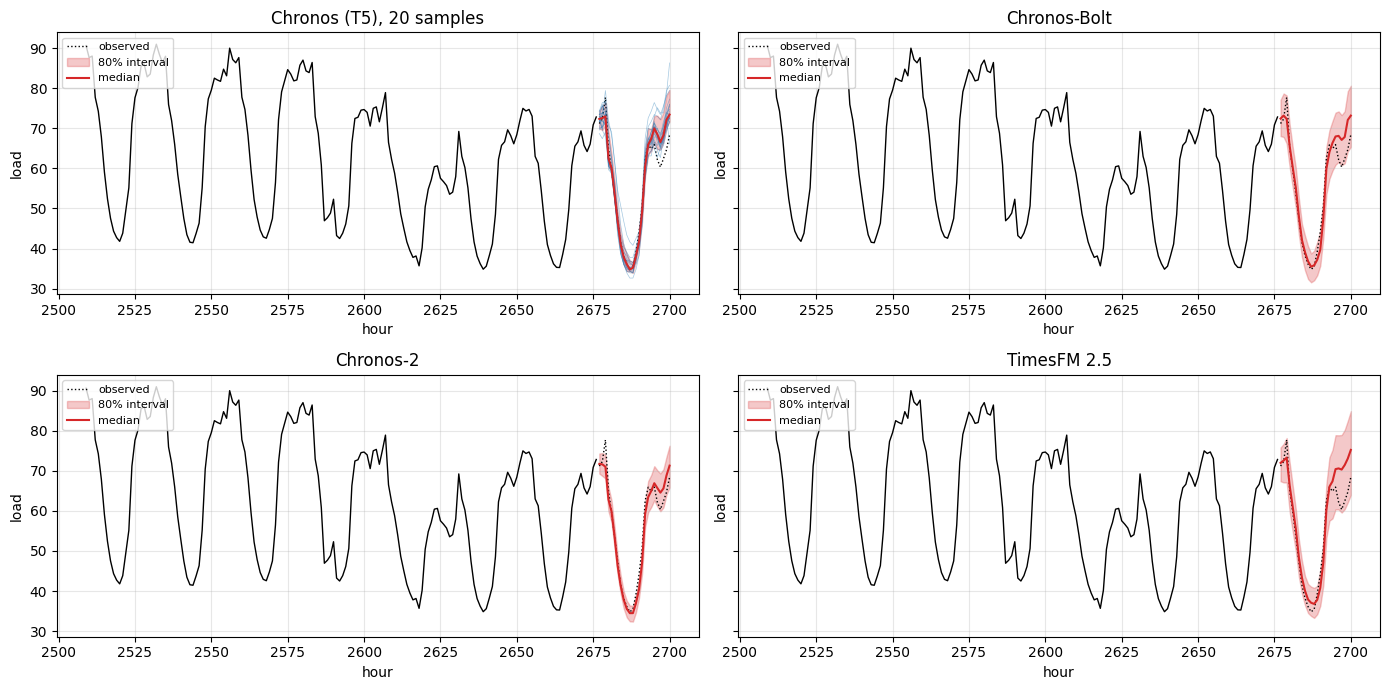

Chronos (T5), 20 samples   MSE of the 24 hourly medians: 10.81
Chronos-Bolt               MSE of the 24 hourly medians: 11.36
Chronos-2                  MSE of the 24 hourly medians: 6.95
TimesFM 2.5                MSE of the 24 hourly medians: 19.48


In [7]:
hours = np.arange(t0 + 1, t0 + 1 + horizon)
first = {"Chronos (T5), 20 samples": np.quantile(samples[0].numpy(), [0.1, 0.5, 0.9], axis=0)}
for name, pipeline in pipelines.items():
    q, _ = pipeline.predict_quantiles([context], prediction_length=horizon, quantile_levels=[0.1, 0.5, 0.9])
    first[name] = (q[0][0] if isinstance(q, list) else q[0]).numpy().T
first["TimesFM 2.5"] = quantiles[0][:, [1, 5, 9]].T

fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharey=True)
for ax, (name, (lo, med, hi)) in zip(axes.ravel(), first.items()):
    run_sequence_plot(x[t0 - 167:t0 + 1], x=np.arange(t0 - 167, t0 + 1), ax=ax, color="black",
                      title=name, xlabel="hour", ylabel="load")
    ax.plot(hours, x[hours], color="black", ls=":", lw=1, label="observed")
    if name.startswith("Chronos (T5)"):
        ax.plot(hours, samples[0].numpy().T, color="tab:blue", lw=0.5, alpha=0.4)
    ax.fill_between(hours, lo, hi, color="tab:red", alpha=0.25, label="80% interval")
    ax.plot(hours, med, color="tab:red", lw=1.5, label="median")
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()
for name, (_, med, _) in first.items():
    print(f"{name:26s} MSE of the 24 hourly medians: {mse(x[hours], med):.2f}")

The four models see the same three weeks, in which the level of the load has dropped: the daily peaks fall from about 90 in the first week to about 75 in the last, and one day, around hour 2620, has a much lower peak. From this history alone, and without having seen the Rome load before, all four forecast the night trough of the next day, its depth and its timing, closely. They differ mostly in the last hours of the day, where the observed load stays below its level of the previous evenings. Over these 24 hours, Chronos-2 has the smallest error and TimesFM the largest, with the widest interval at the end of the day. The sample paths of Chronos spread out with the horizon, and their 10% to 90% range gives an interval like those of the quantile models.

Chronos-Bolt and Chronos-2 make their forecast in a fraction of a second, and TimesFM takes a few seconds on its first call. Chronos needs 2.4 s for its 20 sample paths, because it generates them one token at a time; in our tests, its 300 test forecasts took almost 10 minutes on this computer, for a test MSE of 2.93, and we leave it out of the case study. One forecast origin proves little: we now forecast the 600 hours of the validation and test periods.

## Models we do not run here

**Moirai 2.0** (package `uni2ts`). The model is a PyTorch Lightning module, built from the pretrained module and the forecast settings; `predict` takes a list of contexts, each of shape (time, 1), and returns nine quantiles.

```python
from uni2ts.model.moirai2 import Moirai2Forecast, Moirai2Module

moirai = Moirai2Forecast(module=Moirai2Module.from_pretrained("Salesforce/moirai-2.0-R-small"),
                         prediction_length=24, context_length=512, target_dim=1,
                         feat_dynamic_real_dim=0, past_feat_dynamic_real_dim=0)
quantiles = moirai.predict(past_target=[context.numpy()[:, None]])   # (batch, 9, 24): 10%, ..., 90%
```

The first Moirai models use the GluonTS forecasting library instead: `MoiraiForecast(module=MoiraiModule.from_pretrained("Salesforce/moirai-1.1-R-large"), ...)`, then `create_predictor(batch_size=32)` and `predict` on a GluonTS data set, which return 100 sample paths per forecast.

**Tiny Time Mixers** (package `granite-tsfm`). `get_model` picks, among the TTM models, the one that fits the context and horizon, and returns a Hugging Face model whose forward pass takes a tensor of shape (batch, time, channels) and scales it internally.

```python
from tsfm_public.toolkit.get_model import get_model

ttm = get_model("ibm-granite/granite-timeseries-ttm-r2", context_length=512, prediction_length=24)
with torch.inference_mode():
    output = ttm(past_values=context[None, :, None])               # (batch, time, channels)
forecast = output.prediction_outputs[0, :, 0]                       # 24 point forecasts
```

**Lag-Llama** (installed from its [GitHub repository](https://github.com/time-series-foundation-models/lag-llama), weights from the Hugging Face Hub). The model is a GluonTS estimator, built from the hyperparameters stored in the checkpoint; its predictor returns sample paths.

```python
from gluonts.dataset.pandas import PandasDataset
from lag_llama.gluon.estimator import LagLlamaEstimator

checkpoint = torch.load("lag-llama.ckpt", map_location="cpu", weights_only=False)
args = checkpoint["hyper_parameters"]["model_kwargs"]
estimator = LagLlamaEstimator(ckpt_path="lag-llama.ckpt", prediction_length=24, context_length=32,
                              input_size=args["input_size"], n_layer=args["n_layer"],
                              n_embd_per_head=args["n_embd_per_head"], n_head=args["n_head"],
                              scaling=args["scaling"], time_feat=args["time_feat"],
                              num_parallel_samples=100)
predictor = estimator.create_predictor(estimator.create_transformation(),
                                       estimator.create_lightning_module())
forecasts = list(predictor.predict(PandasDataset(load_df, target="load")))   # 100 paths per series
```

**TimeGPT** (package `nixtla`). The model runs on Nixtla's servers; the client sends a data frame in the long format of the Nixtla libraries, with columns `unique_id`, `ds` and `y`, and receives the forecasts. Prediction intervals, fine-tuning and future covariates are arguments of the calls.

```python
from nixtla import NixtlaClient

client = NixtlaClient(api_key="YOUR_API_KEY")
forecast_df = client.forecast(df=df, h=24, level=[80, 90])          # columns TimeGPT, TimeGPT-lo-80, ...
cv_df = client.cross_validation(df=df, h=24, n_windows=3,
                                finetune_steps=15, finetune_loss="mae")
exog_df = client.forecast(df=df, X_df=future_covariates_df, h=24, level=[80])
```

---

# Case study: forecasting the Rome load zero-shot

## The task

We use the same series and the same task as in Chapters 16 to 19: the first 3,000 hours of the Rome load, the last 300 hours for testing, and a forecast $\tau = 24$ hours ahead, so that every method is scored on the same 300 test hours. As in Chapters 18 and 19, the 300 hours before the test period, 2400 to 2699, form a **validation period**. The trained models of those chapters used it to choose hyperparameters and to stop training; a zero-shot model has nothing to train, and we use the validation period as a second test period, to check that the results do not depend on the 12.5 days of the test period. The models scale every context themselves, so we pass the load as it is.

New self-defined function: `zero_shot`, which forecasts $x(t + 24)$ at a set of origins $t$ from the last `length` hours up to each origin, with any of the three quantile models, and returns the median and the 10% and 90% quantiles.

In [8]:
origins = np.arange(len(x) - horizon)                  # a forecast made at hour t ...
targets = origins + horizon                            # ... is a forecast of hour t + 24
val = (targets >= 2400) & (targets < 2700)
test = targets >= 2700
y_val, y_test = x[targets[val]], x[targets[test]]
naive_val, naive_test = x[origins[val]], x[origins[test]]
test_hours = targets[test]
print(f"validation targets: hours {targets[val][0]}-{targets[val][-1]},  "
      f"test targets: hours {test_hours[0]}-{test_hours[-1]}")
print(f"seasonal naive MSE: validation {mse(y_val, naive_val):.2f},  test {mse(y_test, naive_test):.2f}")


def zero_shot(name, idx, length=context_length):
    """Forecasts of x(t + 24) at the origins t = origins[idx] from the last `length` hours up to t, with
    the model `name`: the median and the 10% and 90% quantiles, each of shape (len(idx),)."""
    windows = [x[max(0, t + 1 - length):t + 1] for t in origins[idx]]
    if name == "TimesFM 2.5":
        _, q = timesfm_model.forecast(horizon=horizon, inputs=windows)
        q = q[:, -1, [1, 5, 9]]                        # index 0 is the mean, then 10%, 20%, ..., 90%
    else:
        q, _ = pipelines[name].predict_quantiles([torch.tensor(w) for w in windows],
                                                 prediction_length=horizon, quantile_levels=[0.1, 0.5, 0.9])
        if isinstance(q, list):                        # Chronos-2: one tensor per series
            q = torch.stack([qq[0] for qq in q])
        q = q[:, -1].numpy()                           # the last of the 24 steps: t + 24
    return q[:, 1], q[:, 0], q[:, 2]

validation targets: hours 2400-2699,  test targets: hours 2700-2999
seasonal naive MSE: validation 47.70,  test 22.29


## How much history?

The only setting of a zero-shot forecast is the length of the context. Chronos-Bolt is the fastest of the three models, so we use it to see how the forecasts change with the context, from one week to 2,048 hours, its maximum. For each context, we report the MSE of the medians and the **coverage** of the 80% interval, the fraction of the 300 hours whose load falls between the 10% and the 90% quantiles, which should be close to 0.80.

In [9]:
rows = []
for length in [168, 336, 512, 1024, 2048]:
    start = time.perf_counter()
    row = {"context (hours)": length}
    for period, idx, y in [("validation", val, y_val), ("test", test, y_test)]:
        median, lo, hi = zero_shot("Chronos-Bolt", idx, length)
        row[f"{period} MSE"] = mse(y, median)
        row[f"{period} coverage"] = np.mean((y >= lo) & (y <= hi))
    row["seconds"] = time.perf_counter() - start
    rows.append(row)
context_table = pd.DataFrame(rows).set_index("context (hours)")
context_table.round(2)

,validation MSE,validation coverage,test MSE,test coverage,seconds
context (hours),,,,,
168,24.17,0.79,6.36,0.91,4.02
336,24.71,0.77,3.42,0.96,7.98
512,17.93,0.84,3.11,0.96,13.62
1024,17.29,0.82,4.50,0.96,20.51
2048,17.80,0.82,4.97,0.97,40.16


One week of context is not enough: with 168 or 336 hours, the validation MSE is about 24, and from 512 hours on, it is between 17.3 and 17.9, almost unchanged up to the maximum of 2,048 hours. The test period ranks the contexts differently: it prefers 336 and 512 hours (3.42 and 3.11) and is worse with longer contexts (4.50 and 4.97). With three weeks, the model sees the daily and the weekly cycles three times, and the recent level of the load; older history adds little and may even mislead. Every context is far better than the seasonal naive forecast on both periods (47.70 and 22.29). The cost grows with the context, from about 4 seconds for the 600 forecasts with one week to about 40 seconds with 2,048 hours. We use 512 hours to compare the models: on the validation period, it is within 4% of the best context, at a third of the cost of the longest one.

The 80% intervals are well calibrated on the validation period, with coverages between 0.77 and 0.84, but too wide on the test period, where they cover 0.91 to 0.97 of the hours. The validation period, in which the level of the load drops, is harder to forecast than the test period, and Chronos-Bolt does not narrow its intervals enough when the series becomes regular again.

## Three models, one context

We now forecast both periods with the three quantile models, with a context of 512 hours.

In [10]:
results, test_forecasts = [], {}
for name in ["Chronos-Bolt", "Chronos-2", "TimesFM 2.5"]:
    start = time.perf_counter()
    row = {"model": name}
    for period, idx, y in [("validation", val, y_val), ("test", test, y_test)]:
        median, lo, hi = zero_shot(name, idx)
        row[f"{period} MSE"] = mse(y, median)
        row[f"{period} coverage"] = np.mean((y >= lo) & (y <= hi))
        if period == "test":
            test_forecasts[name] = (median, lo, hi)
    row["seconds"] = time.perf_counter() - start
    results.append(row)
results.append({"model": "seasonal naive", "validation MSE": mse(y_val, naive_val), "test MSE": mse(y_test, naive_test)})
zero_shot_table = pd.DataFrame(results).set_index("model")
zero_shot_table.round(2)

,validation MSE,validation coverage,test MSE,test coverage,seconds
model,,,,,
Chronos-Bolt,17.93,0.84,3.11,0.96,10.71
Chronos-2,13.64,0.85,3.21,0.78,54.16
TimesFM 2.5,29.14,0.88,4.83,0.93,116.37
seasonal naive,47.70,NaN,22.29,NaN,NaN


All three models beat the seasonal naive forecast by a wide margin on both periods. On the test period, their MSEs are 3.11 (Chronos-Bolt), 3.21 (Chronos-2) and 4.83 (TimesFM 2.5), against 22.29, and on the validation period, 17.93, 13.64 and 29.14, against 47.70. As in Chapters 18 and 19, the validation period is the harder of the two for every model. The two periods do not rank the models in the same way: Chronos-2 is clearly the best on the validation period and close to the best on the test period, while TimesFM is the weakest on both.

Chronos-2 is also the only model whose 80% intervals have about the right coverage on both periods (0.85 and 0.78); Chronos-Bolt and TimesFM give intervals that are too wide on the test period (0.96 and 0.93). The costs differ by an order of magnitude: on a CPU with four threads, Chronos-Bolt makes the 600 forecasts in about 11 seconds, Chronos-2 in about 54 and TimesFM 2.5 in about 116.

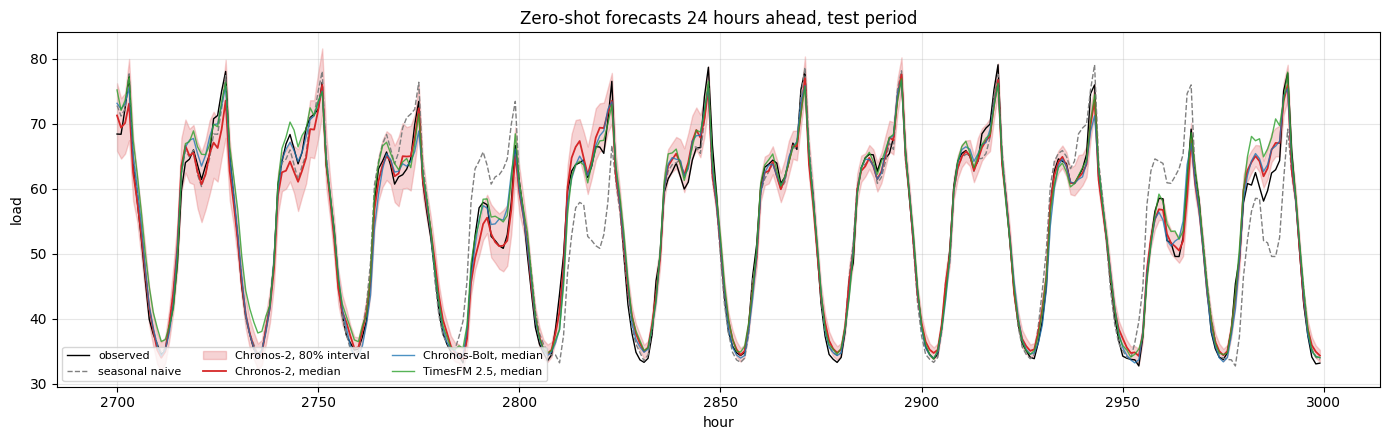

In [11]:
best = zero_shot_table["validation MSE"].idxmin()
median, lo, hi = test_forecasts[best]
ax = run_sequence_plot(y_test, x=test_hours, color="black", figsize=(14, 4.5), label="observed",
                       xlabel="hour", ylabel="load", title="Zero-shot forecasts 24 hours ahead, test period")
ax.plot(test_hours, naive_test, color="gray", ls="--", lw=1, label="seasonal naive")
ax.fill_between(test_hours, lo, hi, color="tab:red", alpha=0.2, label=f"{best}, 80% interval")
ax.plot(test_hours, median, color="tab:red", lw=1.3, label=f"{best}, median")
for name, color in [("Chronos-Bolt", "tab:blue"), ("TimesFM 2.5", "tab:green")]:
    if name != best:
        ax.plot(test_hours, test_forecasts[name][0], color=color, lw=1, alpha=0.8, label=f"{name}, median")
ax.legend(ncol=3, fontsize=8, loc="lower left"); plt.tight_layout(); plt.show()

The plot shows the test forecasts of Chronos-2, the model with the lowest validation MSE, with its 80% interval, and the medians of the other two models. The three forecasts follow the observed load closely, and each other even more closely. Most remarkably, they anticipate both low days of the test period, around hours 2790 and 2955, and they do not repeat them on the following days, as the seasonal naive forecast does. Of all the models of Chapters 16 to 19, only the attention forecast of Chapter 19, which compares the last week with every week of the history, anticipated the low days, and only in part. Where the forecasts are least sure, at the start of the test period and on the first low day, the interval of Chronos-2 widens, and it mostly contains the observed load. The visible misses are small: Chronos-2 forecasts the low day at hour 2790 a little too low, and TimesFM the evening of hour 2985 too high.

## Comparison with the earlier chapters

In [12]:
comparison = pd.DataFrame({
    "test MSE": [mse(y_test, naive_test), 18.48, 12.45, 16.17, 14.47, 8.76, 16.47,
                 *zero_shot_table.loc[["Chronos-Bolt", "Chronos-2", "TimesFM 2.5"], "test MSE"]],
    "trained on the Rome load": ["no", "yes", "yes", "yes", "yes", "no", "yes", "no", "no", "no"],
    "source": ["computed above", "Chapter 16", "Chapter 16", "Chapter 17", "Chapter 18", "Chapter 19",
               "Chapter 19", "computed above", "computed above", "computed above"]},
    index=["seasonal naive", "MLP, 48-hour window (mean of 3 seeds)", "linear, 168-hour window",
           "ESN, 900 units, ridge readout", "LSTM, ensemble of 5 seeds", "attention forecast, no training",
           "transformer, ensemble of 5 seeds", "Chronos-Bolt, zero-shot", "Chronos-2, zero-shot",
           "TimesFM 2.5, zero-shot"])
comparison.round(2)

,test MSE,trained on the Rome load,source
seasonal naive,22.29,no,computed above
"MLP, 48-hour window (mean of 3 seeds)",18.48,yes,Chapter 16
"linear, 168-hour window",12.45,yes,Chapter 16
"ESN, 900 units, ridge readout",16.17,yes,Chapter 17
"LSTM, ensemble of 5 seeds",14.47,yes,Chapter 18
"attention forecast, no training",8.76,no,Chapter 19
"transformer, ensemble of 5 seeds",16.47,yes,Chapter 19
"Chronos-Bolt, zero-shot",3.11,no,computed above
"Chronos-2, zero-shot",3.21,no,computed above
"TimesFM 2.5, zero-shot",4.83,no,computed above


Without any training on the Rome load, the three foundation models have the lowest test MSEs of Chapters 16 to 20. Chronos-Bolt and Chronos-2 reach about a third of the MSE of the attention forecast of Chapter 19 (8.76), the best model so far, and a quarter of that of the linear model with a one-week window (12.45). The neural networks that we trained on the 2,700 hours of the series, the Multi-Layer Perceptron (MLP), the Echo State Network (ESN), the Long Short-Term Memory (LSTM) network and the transformer, with test MSEs between 14.47 and 18.48, are four to six times worse than Chronos-Bolt. The validation period tells the same story: Chronos-2 reaches 13.64 there, against 29.21 for the attention forecast and 26.28 to 36.52 for the single LSTMs of Chapter 18.

This is the situation for which foundation models were made. Chapters 18 and 19 ended with the same diagnosis: a network trained on 2,700 hours of one series did not learn that the load one week earlier anticipates the low days, and the remedy was more data. The foundation models were trained on billions of observations, in which daily and weekly cycles, changes of level and low days are common, and they recognize these patterns in three weeks of context.

Three caveats apply. First, the test period is only 12.5 days long, as in the earlier chapters, although the validation period confirms the ranking. Second, the Rome load is a public data set, and we cannot check whether it, or a series like it, was part of the training collections of these models: data leakage cannot be ruled out. Third, all the models compared here are univariate; a model with temperature and calendar covariates might narrow the gap, and Chronos-2 could use them as well. Still, a zero-shot forecast is a benchmark that every new forecasting model should now be compared with: it takes a few lines of code and no training at all.

---

# Summary

**Foundation models in Python**: every open model is a PyTorch `nn.Module` whose weights are downloaded from the Hugging Face Hub with `from_pretrained`, wrapped in a package that scales and tokenizes the contexts and returns forecasts.

- **PyTorch.** Contexts are 32-bit tensors, batched as rows of shape (batch, time), or lists of tensors of different lengths, left-padded with `torch.nan`; the packages run the networks in inference mode, on the CPU or a graphics card.
- **The functions.** Chronos, Chronos-Bolt and Chronos-2: `BaseChronosPipeline.from_pretrained(name)`, then `predict` (samples) or `predict_quantiles` (quantiles and a point forecast); Chronos-2 adds covariates, `predict_df` and `fit`. TimesFM 2.5: `from_pretrained`, `compile(ForecastConfig(...))` and `forecast(horizon, inputs)`, which returns the point forecasts and ten quantile forecasts, the mean first. Moirai 2.0: `Moirai2Forecast(...).predict`. Tiny Time Mixers: `get_model(...)` and a forward pass. Lag-Llama: a GluonTS estimator. TimeGPT: `NixtlaClient(api_key).forecast(df, h)`.
- **The case study.** With a context of 512 hours and no training, Chronos-Bolt, Chronos-2 and TimesFM 2.5 forecast the Rome load 24 hours ahead with test MSEs of 3.11, 3.21 and 4.83, against 22.29 for the seasonal naive forecast and 8.76 for the best model of Chapters 16 to 19, and with validation MSEs of 17.93, 13.64 and 29.14, against 47.70. They anticipated the low days that the trained networks missed. One week of context was not enough, and beyond three weeks, more history did not help. Chronos-2 had the best-calibrated 80% intervals. The original Chronos, which samples one token at a time, was too slow on a CPU for hundreds of forecasts.